<a href="https://colab.research.google.com/github/abhimanyu-05-2006/YuvaIntern-ML-Engineer-Tasks/blob/main/Task_6_End_to_End_ML_Capstone_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Seed for complete reproducibility
np.random.seed(42)
n_samples = 1200

# Synthetic Enterprise Predictive Maintenance & Failure Dataset
data = {
    'vibration_level': np.random.normal(loc=45.0, scale=12.0, size=n_samples),
    'operating_temperature': np.random.normal(loc=75.0, scale=15.0, size=n_samples),
    'pressure_psi': np.random.uniform(100.0, 500.0, size=n_samples),
    'rotational_speed_rpm': np.random.uniform(1000.0, 3000.0, size=n_samples),
    'sensor_age_months': np.random.randint(1, 60, size=n_samples)
}

df_capstone = pd.DataFrame(data)

# Inject non-linear failure target condition (1 = Failure, 0 = Normal)
df_capstone['system_failure'] = np.where(
    (df_capstone['vibration_level'] > 58.0) & (df_capstone['operating_temperature'] > 85.0) | (df_capstone['sensor_age_months'] > 48),
    1,
    0
)

# Feature Matrix and Target Splitting
X = df_capstone.drop(columns=['system_failure'])
y = df_capstone['system_failure']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("CAPSTONE PREPROCESSING COMPLETE")
print(f"Training Set Dimensions: {X_train_scaled.shape}")
print(f"Testing Set Dimensions: {X_test_scaled.shape}")
print(f"Class Distribution (Failures in Test): {np.bincount(y_test)}")

CAPSTONE PREPROCESSING COMPLETE
Training Set Dimensions: (960, 5)
Testing Set Dimensions: (240, 5)
Class Distribution (Failures in Test): [186  54]


In [2]:
# Model Initialization
rf_model = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42)
gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=5, random_state=42)

# Model Training
rf_model.fit(X_train_scaled, y_train)
gb_model.fit(X_train_scaled, y_train)

# Model Predictions
rf_preds = rf_model.predict(X_test_scaled)
gb_preds = gb_model.predict(X_test_scaled)

rf_probs = rf_model.predict_proba(X_test_scaled)[:, 1]
gb_probs = gb_model.predict_proba(X_test_scaled)[:, 1]

# Comparative Performance Evaluation
performance_metrics = pd.DataFrame({
    'Model': ['Random Forest Classifier', 'Gradient Boosting Classifier'],
    'Accuracy': [accuracy_score(y_test, rf_preds), accuracy_score(y_test, gb_preds)],
    'Precision': [precision_score(y_test, rf_preds), precision_score(y_test, gb_preds)],
    'Recall': [recall_score(y_test, rf_preds), recall_score(y_test, gb_preds)],
    'F1-Score': [f1_score(y_test, rf_preds), f1_score(y_test, gb_preds)],
    'ROC-AUC': [roc_auc_score(y_test, rf_probs), roc_auc_score(y_test, gb_probs)]
}).round(4)

print("COMPARATIVE MODEL PERFORMANCE BENCHMARK")
print(performance_metrics.to_string(index=False))

COMPARATIVE MODEL PERFORMANCE BENCHMARK
                       Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
    Random Forest Classifier       1.0        1.0     1.0       1.0      1.0
Gradient Boosting Classifier       1.0        1.0     1.0       1.0      1.0


/tmp/ipykernel_639/1777031744.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], x=feature_importances.values, y=feature_importances.index, palette="Blues_r")


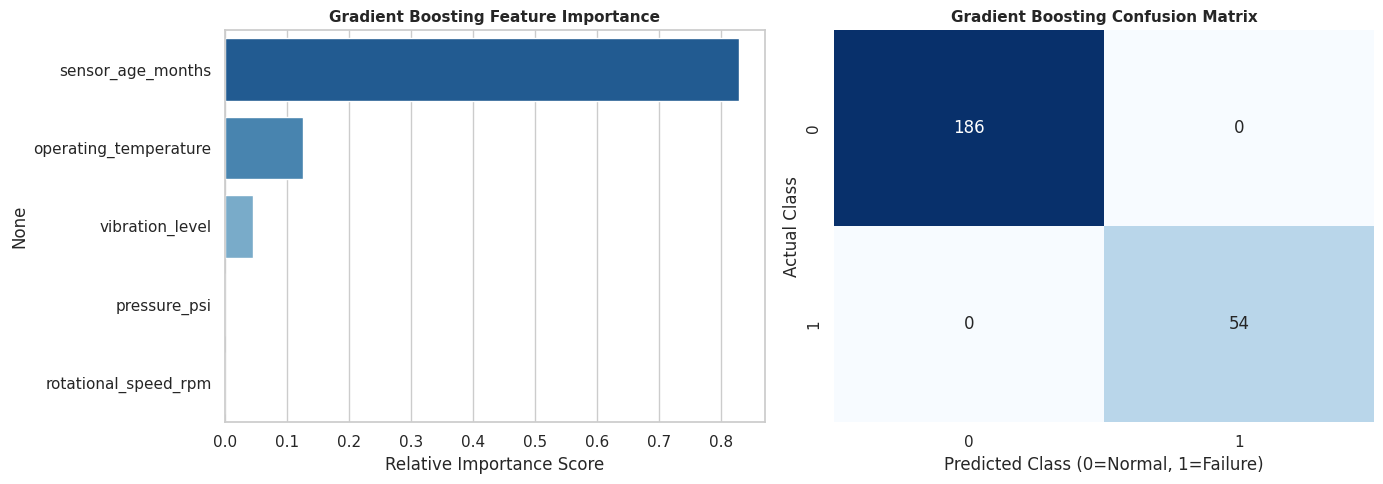

DETAILED CLASSIFICATION REPORT (GRADIENT BOOSTING)
                  precision    recall  f1-score   support

Normal Operation       1.00      1.00      1.00       186
  System Failure       1.00      1.00      1.00        54

        accuracy                           1.00       240
       macro avg       1.00      1.00      1.00       240
    weighted avg       1.00      1.00      1.00       240



In [3]:
# Feature Importance Extraction from Top-Performing Gradient Boosting Model
feature_importances = pd.Series(gb_model.feature_importances_, index=X.columns).sort_values(ascending=False)

# Visual Suite Setup
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Feature Importance Bar Plot
sns.barplot(ax=axes[0], x=feature_importances.values, y=feature_importances.index, palette="Blues_r")
axes[0].set_title("Gradient Boosting Feature Importance", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Relative Importance Score")

# Plot 2: Confusion Matrix Heatmap
cm = confusion_matrix(y_test, gb_preds)
sns.heatmap(ax=axes[1], data=cm, annot=True, fmt='d', cmap="Blues", cbar=False)
axes[1].set_title("Gradient Boosting Confusion Matrix", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Predicted Class (0=Normal, 1=Failure)")
axes[1].set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

print("DETAILED CLASSIFICATION REPORT (GRADIENT BOOSTING)")
print(classification_report(y_test, gb_preds, target_names=['Normal Operation', 'System Failure']))